# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Epinnn14/Flyrank-ML-Intern/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

**Question.** Using only what is known *before* a 30-day window starts, can we rank a client's pages
so that the ones about to lose search impressions are reviewed first, better than the current
rule or random order?

**The decision it supports.** A content editor has about 50 review slots a week across thousands
of pages. Which pages should they open first, and what kind of fix should they consider (refresh,
expand, rewrite the snippet, consolidate, or leave alone)?

**Why it matters for FlyRank.** FlyRank manages large AI-assisted content portfolios. Pages lose
visibility as they age and competitors publish, but nobody can re-read every page every month. A
ranked, explained queue turns "refresh old content" into "refresh *these* pages first, for these
reasons". This is lane **Search Traffic Decline Prediction** (closest predefined lane:
*Refresh / Content Opportunity Scoring*).

In [1]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

import os, sys, subprocess, json, shutil, warnings
warnings.filterwarnings("ignore", category=UserWarning)
REPO_DIR = "Flyrank-ML-Intern"
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Epinnn14/Flyrank-ML-Intern"
if IN_COLAB:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, REPO_DIR], check=True)
    os.chdir(REPO_DIR)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("../..")
sys.path.insert(0, "scripts")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, ml_utils as mu
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
RANDOM_STATE = 42
os.makedirs("work/figures", exist_ok=True); os.makedirs("work/outputs", exist_ok=True)

QUESTION = ("Using only what is known before a 30-day window starts, can we rank a client's pages so that "
            "the ones about to lose search impressions are reviewed first, better than the current rule "
            "or random order?")
DECISION = "Which ~50 pages should a content editor review first this week, and what kind of fix should they consider?"
print("Question:", QUESTION); print("Decision:", DECISION)

Question: Using only what is known before a 30-day window starts, can we rank a client's pages so that the ones about to lose search impressions are reviewed first, better than the current rule or random order?
Decision: Which ~50 pages should a content editor review first this week, and what kind of fix should they consider?


## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

**Source.** The FlyRank ML Internship **starter dataset**, `data/raw/content_refresh_anonymized.csv`:
30,000 pseudonymized content items from 32 pseudonymized clients. All metrics come from one trailing
90-day snapshot (Google Search Console + GA4), plus 30-day sub-windows (`*_last_30d`,
`*_prev_30d`). I did not use the 79M-row warehouse release for the final model. The slice is a
documented teaching subset of it, and all claims here are scoped to the slice.

**Filters (all from the reference pipeline):** impressions_90d > 0 and content age ≥ 90 days, plus
de-duplication on `content_id`. None of these dropped rows in this slice. No outcome-window
information is used to select rows.

**What is deliberately not used:** client and content ids (grouping only), the label sources
`trend_direction` / `trend_pct`, generator metadata (`provider_used`, `model_used`), and any
column whose window overlaps the label (see Methodology).

**Public-safety:** no client names, domains, URLs or queries exist in this data, and none appear in
the paper.

In [2]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

raw = pd.read_csv("data/raw/content_refresh_anonymized.csv")
print(f"Raw file: {raw.shape[0]:,} rows x {raw.shape[1]} columns, {raw['client_id'].nunique()} pseudonymized clients")
df = raw.copy()
for col in mu.NUMERIC_COLUMNS:
    df[col] = pd.to_numeric(df[col], errors="coerce")
for col in mu.CATEGORICAL_COLUMNS:
    df[col] = df[col].fillna("unknown").astype(str).replace({"": "unknown", "nan": "unknown"})
n0 = len(df)
df = df[df["impressions_90d"] > 0]; n1 = len(df)
df = df[df["content_age_days"] >= 90]; n2 = len(df)
df = df.drop_duplicates("content_id").reset_index(drop=True); n3 = len(df)
print(f"Exclusions: impressions_90d > 0 -> dropped {n0-n1}; age >= 90 days -> dropped {n1-n2}; duplicate ids -> dropped {n2-n3}")
df["is_declining_label"] = (df["trend_direction"] == "down").astype(int)
print(f"Final: {len(df):,} pages | label base rate {df['is_declining_label'].mean():.3f}")
print("\nLabel source (trend_direction) counts:"); print(df["trend_direction"].value_counts().to_string())
print("\nContent types:"); print(df["content_type"].value_counts().to_string())
cl = df.groupby("client_id").size()
print(f"\nPages per client: min {cl.min()}, median {int(cl.median())}, max {cl.max()}")

Raw file: 30,000 rows x 44 columns, 32 pseudonymized clients


Exclusions: impressions_90d > 0 -> dropped 0; age >= 90 days -> dropped 0; duplicate ids -> dropped 0
Final: 30,000 pages | label base rate 0.542

Label source (trend_direction) counts:
trend_direction
down      16262
stable     5962
up         4388
new        2236
flat       1152

Content types:
content_type
keyword article       27207
feedly article         2096
comparison article      697

Pages per client: min 3, median 567, max 7008


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

**Label.** `is_declining_label = 1` when `trend_direction == "down"`, meaning impressions in the
last 30 days fell by more than 20% vs the previous 30 days. Base rate: **0.542**.

**Prediction moment and features (window alignment).** The label compares days 1–30 back with
days 31–60 back. A prediction is only useful *before* days 1–30 happen, so features may use
**days 31–90 back only**:

- previous-30 and first-30 impressions / clicks / sessions (log). The first-30 window is
  derived as `90d − last30 − prev30`.
- `early_momentum` (prev-30 vs first-30 impressions)
- content age (shifted to the prediction moment), word count, keyword volume / competition / CPC,
  missingness flags, content type, intent, competition level

Dropped: every `*_90d` total and rate (they contain the label window) and
`days_since_last_update` (68% of pages were updated *inside* the label window).

**Baselines on the same split:** (1) random order, (2) the **Week-4 rule**
(0.5·staleness + 0.3·visibility + 0.2·position opportunity), (3) a **momentum rule** ("pages that
were already falling keep falling").

**Models:** logistic regression (scaled), then random forest (300 trees, depth ≤ 12, leaf ≥ 20).

**Validation:** `GroupKFold(5)` by `client_id`. Every score comes from clients the model never
saw. Metrics: precision@50 / @100 (the editor's real batch size), ROC AUC, average precision, and
the base rate printed alongside.

**Leakage checks (from `w06_validation_audit`):** adding `trend_pct` pushes AUC to 1.00, so the
harness catches leaks. A random row split inflates AUC by about 0.10 vs the grouped split.
Window-aligned features score about the same as the overlapping ones (0.685 vs 0.668), so the
honest feature set costs nothing.

In [3]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score

for c in ["impressions", "clicks", "sessions"]:
    df[f"{c}_first30"] = (df[f"{c}_90d"] - df[f"{c}_last_30d"].fillna(0) - df[f"{c}_prev_30d"].fillna(0)).clip(lower=0)

def aligned_features(frame):
    """Days 31-90 back only: everything knowable before the label window starts."""
    out = pd.DataFrame(index=frame.index)
    for c in ["search_volume", "competition", "cpc", "word_count"]:
        out[c] = frame[c]
    out["has_search_volume"] = frame["search_volume"].notna().astype(int)
    out["has_word_count"] = frame["word_count"].notna().astype(int)
    out["content_age_days"] = frame["content_age_days"] - 30
    for c in ["impressions", "clicks", "sessions"]:
        out[f"log_{c}_recent"] = np.log1p(frame[f"{c}_prev_30d"].fillna(0))
        out[f"log_{c}_earlier"] = np.log1p(frame[f"{c}_first30"])
    out["early_momentum"] = out["log_impressions_recent"] - out["log_impressions_earlier"]
    cats = pd.get_dummies(frame[["competition_level", "content_type", "main_intent"]].astype(str), dtype=float)
    return pd.concat([out.fillna(0), cats], axis=1)

X = aligned_features(df)
y = df["is_declining_label"].to_numpy(); groups = df["client_id"].to_numpy()
print(f"Feature matrix: {X.shape[0]:,} x {X.shape[1]}")
forbidden = ["trend_pct", "trend_direction", "client_id", "content_id", "impressions_last_30d", "days_since_last_update"]
print("Forbidden columns present:", [f for f in forbidden if any(col.startswith(f) for col in X.columns)] or "none")

# Baseline 1: the Week-4 rule (stale + visible + position opportunity), unchanged
df["baseline_week4"] = (0.5 * df["days_since_last_update"] / df["days_since_last_update"].max()
                        + 0.3 * df["impressions_90d"] / df["impressions_90d"].max()
                        + 0.2 * (100 - df["avg_position"]).clip(lower=0) / 100)
# Baseline 2: a one-line momentum rule a human could apply with no ML
df["baseline_momentum"] = -X["early_momentum"]

MODELS = {
    "logistic_regression": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "random_forest": lambda: RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=20,
                                                    n_jobs=-1, random_state=RANDOM_STATE),
}
rows, oof = [], {k: np.zeros(len(df)) for k in MODELS}
for fold, (tr, te) in enumerate(GroupKFold(5).split(X, y, groups)):
    scores = {"random_order": np.random.default_rng(fold).random(len(te)),
              "rule_week4": df["baseline_week4"].to_numpy()[te],
              "rule_momentum": df["baseline_momentum"].to_numpy()[te]}
    for name, make in MODELS.items():
        m = make().fit(X.iloc[tr], y[tr]); p = m.predict_proba(X.iloc[te])[:, 1]
        scores[name] = p; oof[name][te] = p
    for name, s in scores.items():
        rows.append({"method": name, "fold": fold, "base_rate": y[te].mean(),
                     "roc_auc": roc_auc_score(y[te], s), "avg_precision": average_precision_score(y[te], s),
                     "precision_at_50": mu.precision_at_k(y[te], s, 50), "precision_at_100": mu.precision_at_k(y[te], s, 100)})
cv = pd.DataFrame(rows)
print("\nValidation: GroupKFold(5) by client — every score below is on clients the model never saw.")

Feature matrix: 30,000 x 26
Forbidden columns present: none



Validation: GroupKFold(5) by client — every score below is on clients the model never saw.


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

**Headline (client-grouped 5-fold, mean):**

| Method | ROC AUC | Avg precision | Precision@50 | Precision@100 |
|---|---|---|---|---|
| Random order | 0.51 | 0.55 | 0.50 | 0.52 |
| Week-4 rule | 0.50 | 0.55 | 0.44 | 0.44 |
| Momentum rule | 0.48 | 0.52 | 0.19 | 0.28 |
| **Logistic regression** | **0.70** | **0.70** | **0.84** | **0.82** |
| Random forest | 0.69 | 0.68 | 0.65 | 0.68 |

Base rate 0.544 (0.38–0.65 per fold).

**How to read it:**

- Both rules do no better than random **on this label**. The Week-4 rule answers a different
  question ("stale but visible?"), and the momentum rule is *worse* than random: pages that fell
  in the earlier window tended to bounce back (mean reversion), not keep falling.
- Logistic regression put about **42 real decliners in a top-50 list vs about 27 for random
  order** (0.84 vs 0.54). It beat the forest at the top of the list in all five folds
  (0.74–0.92 vs 0.36–0.76), with similar AUC. So the simpler model is the recommendation.
- AUC around 0.70 means the ranking is useful for ordering a queue but weak at separating any
  single page: decision-support, not a verdict.

Base rate (share of pages that declined), mean over folds: 0.544

                     roc_auc  avg_precision  precision_at_50  precision_at_100  roc_auc_sd
method                                                                                    
random_order           0.506          0.550            0.500             0.524       0.012
rule_week4             0.503          0.553            0.444             0.442       0.059
rule_momentum          0.483          0.519            0.192             0.276       0.057
logistic_regression    0.696          0.704            0.844             0.824       0.083
random_forest          0.685          0.677            0.648             0.684       0.079


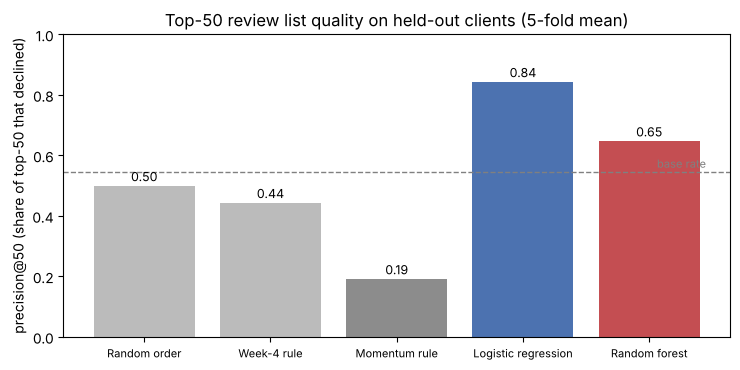

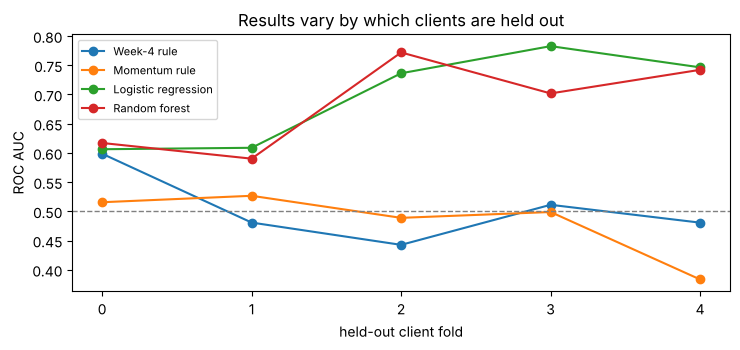


Saved work/outputs/capstone_metrics.json


In [4]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

order = ["random_order", "rule_week4", "rule_momentum", "logistic_regression", "random_forest"]
table = cv.groupby("method")[["roc_auc", "avg_precision", "precision_at_50", "precision_at_100"]].mean().loc[order]
spread = cv.groupby("method")["roc_auc"].std().loc[order]
table["roc_auc_sd"] = spread
table = table.round(3)
print(f"Base rate (share of pages that declined), mean over folds: {cv['base_rate'].mean():.3f}\n")
print(table.to_string())

fig, ax = plt.subplots(figsize=(7.5, 3.8))
labels = {"random_order": "Random order", "rule_week4": "Week-4 rule", "rule_momentum": "Momentum rule",
          "logistic_regression": "Logistic regression", "random_forest": "Random forest"}
vals = table["precision_at_50"]; colors = ["#BBBBBB", "#BBBBBB", "#8C8C8C", "#4C72B0", "#C44E52"]
ax.bar([labels[k] for k in order], vals, color=colors)
for i, v in enumerate(vals):
    ax.text(i, v + 0.015, f"{v:.2f}", ha="center", fontsize=9)
ax.axhline(cv["base_rate"].mean(), ls="--", color="grey", lw=1)
ax.text(4.45, cv["base_rate"].mean() + 0.015, "base rate", ha="right", fontsize=8, color="grey")
ax.set_ylim(0, 1); ax.set_ylabel("precision@50 (share of top-50 that declined)")
ax.set_title("Top-50 review list quality on held-out clients (5-fold mean)")
plt.xticks(fontsize=8); plt.tight_layout(); plt.savefig("work/figures/capstone_results_p50.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 3.6))
for name in ["rule_week4", "rule_momentum", "logistic_regression", "random_forest"]:
    ax.plot(cv[cv.method == name]["fold"], cv[cv.method == name]["roc_auc"], marker="o", label=labels[name])
ax.axhline(0.5, ls="--", color="grey", lw=1); ax.set_xticks(range(5)); ax.set_xlabel("held-out client fold")
ax.set_ylabel("ROC AUC"); ax.set_title("Results vary by which clients are held out"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("work/figures/capstone_auc_by_fold.png", dpi=150); plt.show()

results = {"base_rate": round(float(cv["base_rate"].mean()), 4),
           "table": table.reset_index().to_dict(orient="records"),
           "validation": "GroupKFold(5) by client_id, window-aligned features (days 31-90 back)"}
json.dump(results, open("work/outputs/capstone_metrics.json", "w"), indent=2)
print("\nSaved work/outputs/capstone_metrics.json")

## 5. Limitations

*What this work cannot claim.*

- **Observational, one snapshot.** One 90-day export and one forward step. Nothing here shows that
  refreshing a page *causes* recovery. Pages that were updated declined less often, but editors
  chose which pages to update.
- **Starter slice, not the warehouse.** 30k pages from 32 clients. Clients range from 3 to 7,008
  pages, and each fold held out ~6 clients. Results vary by fold (RF AUC 0.59–0.77). A new client
  could land anywhere in that range.
- **Short, noisy label.** A 20% 30-day swing can come from seasonality, a tracking change or a
  search-engine update rather than page quality. The label measures momentum, not health.
- **Age is a cohort marker.** Pages were published in batches, so `content_age_days` partly encodes
  "which publishing batch". The model may be learning batch timing as much as ageing.
- **Missing data.** 26% of pages lack word count and 8% lack keyword data, so some reason codes
  cannot fire for them.
- **No live outcome yet.** The forward queue (`risk_next30`) has not been checked against what
  happened next month. Monitoring triggers are defined in `w07_action_playbook`.
- **Not Google's algorithm.** This models outcomes inside one portfolio. It says nothing general
  about how search ranking works.

In [5]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

# Numbers behind the limitations, so every limit is measured rather than asserted.
rf = cv[cv.method == "random_forest"]
print(f"RF ROC AUC range across folds: {rf['roc_auc'].min():.3f} - {rf['roc_auc'].max():.3f}")
print(f"Fold base rates: {rf['base_rate'].round(2).tolist()}")
ages = df["content_age_days"].value_counts()
print(f"Distinct content ages: {ages.size}; top-5 ages cover {ages.head(5).sum()/len(df):.0%} of pages (batch publishing)")
print(f"Pages missing word count: {df['word_count'].isna().mean():.1%}; missing keyword data: {df['search_volume'].isna().mean():.1%}")
print(f"Label threshold: 'down' = >20% drop in impressions, last 30 vs previous 30 days")

RF ROC AUC range across folds: 0.590 - 0.772
Fold base rates: [0.49, 0.65, 0.38, 0.62, 0.58]
Distinct content ages: 225; top-5 ages cover 12% of pages (batch publishing)
Pages missing word count: 25.7%; missing keyword data: 8.2%
Label threshold: 'down' = >20% drop in impressions, last 30 vs previous 30 days


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

From `w07_action_playbook` (logistic regression, scored one window forward, explained with
transparent reason codes). In priority order:

1. **`refresh_now` / `expand_and_refresh` (~4,100 pages):** high predicted risk *and* still ≥ 300
   impressions a month. Review first: update facts and examples, add missing subtopics, and expand
   if under 2,000 words. Check impressions/clicks/position after 30 and 60 days.
2. **`rewrite_title_and_meta` (~2,200):** ranking on pages 1–2 but CTR below its tier median.
   This is a snippet problem, not a content problem. Tighten the title and description around
   the search intent.
3. **`light_refresh_or_monitor` (~1,400):** risky but little demand. Small fixes only.
4. **`consolidate_or_prune_review` (~850):** < 10 impressions a month and over a year old. A
   **human-only** decision: merge, redirect or keep. Never automated.
5. **`protect` (~6,700) / `monitor` (~14,700):** healthy or quiet. Leave alone and watch the
   triggers.

**Never automate:** deletes, merges, redirects, no-index, publishing AI-drafted rewrites, or title
changes on top-traffic pages. Every batch starts with a two-minute human check per page.

In [6]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

play = json.load(open("work/outputs/w07_playbook_metrics.json"))
top20 = pd.read_json("work/outputs/action_queue_top20_public.json")
print("Action mix (from w07_action_playbook):")
print(pd.Series(play["action_mix"]).to_string())
print("\nTop 10 of the review queue (public-safe, no ids):")
print(top20.head(10).to_string(index=False))

Action mix (from w07_action_playbook):
monitor                        14715
protect                         6747
refresh_now                     3991
rewrite_title_and_meta          2212
light_refresh_or_monitor        1366
consolidate_or_prune_review      849
expand_and_refresh               120

Top 10 of the review queue (public-safe, no ids):
 rank archetype_action  risk_next30  impressions_last_30d  clicks_last_30d  content_age_days  word_count    content_type                                                                             reason_codes
    1      refresh_now        0.948                212015                8                98      3530.0 keyword article                                                       high_model_risk|demand_still_there
    2      refresh_now        0.939                122303               10               148      4939.0 keyword article                                                       high_model_risk|demand_still_there
    3      refresh_no

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

The cell below copies the figures the deployed paper embeds into `docs/paper-assets/` and confirms
the metric receipts exist. The paper itself is `docs/index.html`, served by GitHub Pages from `/docs`.

In [7]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

# Copy the figures the deployed paper (docs/index.html) embeds, and verify every metric file exists.
os.makedirs("docs/paper-assets", exist_ok=True)
figs = ["capstone_results_p50.png", "capstone_auc_by_fold.png", "w06_split_before_after.png",
        "w07_action_mix.png", "w07_decay_by_age.png", "w07_reason_codes.png"]
for f in figs:
    shutil.copy(f"work/figures/{f}", f"docs/paper-assets/{f}")
    print(f"docs/paper-assets/{f:32s} {os.path.getsize('docs/paper-assets/' + f):>8,} bytes")
for f in ["w06_validation_metrics.json", "w07_playbook_metrics.json", "capstone_metrics.json"]:
    print(f"work/outputs/{f:32s} exists: {os.path.exists('work/outputs/' + f)}")
paper_url = open("submission/paper_url.txt").read().strip()
print("\nsubmission/paper_url.txt ->", paper_url)

docs/paper-assets/capstone_results_p50.png           56,507 bytes
docs/paper-assets/capstone_auc_by_fold.png           81,306 bytes
docs/paper-assets/w06_split_before_after.png         48,971 bytes
docs/paper-assets/w07_action_mix.png                 60,098 bytes
docs/paper-assets/w07_decay_by_age.png               53,822 bytes
docs/paper-assets/w07_reason_codes.png               55,160 bytes
work/outputs/w06_validation_metrics.json      exists: True
work/outputs/w07_playbook_metrics.json        exists: True
work/outputs/capstone_metrics.json            exists: True

submission/paper_url.txt -> https://epinnn14.github.io/Flyrank-ML-Intern/


## 8. Demo outline (5 minutes) — for the Week-8 showcase

| Time | Beat | What I show / say |
|---|---|---|
| 0:00–0:40 | **Question** | "An editor has 50 review slots a week and 30,000 pages. Which 50 first?" |
| 0:40–1:40 | **Method** | Label = >20% drop in impressions (last 30 vs previous 30 days). Features only from *before* that window. Validation holds out whole clients, so every number is on clients the model never saw. |
| 1:40–2:50 | **One chart** | `capstone_results_p50.png`: the old rule and a momentum rule do no better than random; logistic regression gets ~42 real decliners in a top-50 list vs ~27 by chance. |
| 2:50–3:50 | **One honest result** | `w06_split_before_after.png`: a random split made the same model look 0.10 AUC better than it is. The momentum rule is worse than random (pages bounce back). AUC ≈ 0.70: good for ordering a queue, not for judging one page. |
| 3:50–4:40 | **One recommendation** | Start each week with the `refresh_now` pages that still have demand. Rewrite titles where CTR lags. Never auto-prune. |
| 4:40–5:00 | **Close** | Limits (one snapshot, starter slice, observational) + link to the paper and repo. |

## 9. Two shareable cuts

**Social post (methodology):**

> I spent my FlyRank ML internship capstone asking a simple question: if an editor can only
> review 50 pages a week, which 50?
>
> The hardest part wasn't the model. It was being honest about validation. Scoring my model on a
> random split made it look ~0.10 AUC better than it really is on a brand-new client. I also found
> that several "obvious" features shared a time window with the label, so I rebuilt everything
> from data available *before* the outcome.
>
> Result on held-out clients: a plain logistic regression puts ~42 pages that really declined into
> a top-50 review list, vs ~27 by chance. The existing rule-of-thumb and a "falling pages keep
> falling" rule did no better than random. It's a decision-support tool for ordering a review
> queue, not a crystal ball.
>
> Paper + notebooks: https://epinnn14.github.io/Flyrank-ML-Intern/
> Built on the FlyRank ML Internship dataset.

**Employer-facing summary (3 sentences):**

> I built a page-decline review queue on the FlyRank ML Internship dataset (30,000 real,
> pseudonymized content pages from 32 clients, Google Search Console + GA4 metrics). Using
> client-grouped validation and features strictly from before the outcome window, a logistic
> regression ranked pages at precision@50 ≈ 0.84 against a 0.54 base rate, while the existing
> heuristic did no better than random. I shipped it as a public research paper with a ranked action
> playbook, explicit limits, and a no-automation list for human review.

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [x] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [x] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
